<a href="https://colab.research.google.com/github/Sarsariintissar/2027-S7-CI/blob/main/Copie_de_Template_Projet_DataScience_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Template étudiant — Data Science et commerce international

**Binôme :** SARSARI INTISSAR / WARAKI AYA / HASSOUN HIBA
**Projet :** Projet N°34
**Date :** 11/11/2026



In [30]:
# Bibliothèques principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, train_test_split
GRAINE_ALEATOIRE = 42
print('Versions :', np.__version__, pd.__version__)

Versions : 2.4.6 2.2.3


In [73]:
import pandas as pd

# Note : Assurez-vous d'avoir exécuté la section 8 (découpage) et la section 12 (entraînement) avant cette cellule
resultats = pd.DataFrame({
    "Observation": X_test["Pays"].values,
    "Prédiction (USD)": modele_lineaire.predict(X_test),
    "Valeur réelle (USD)": y_test.values
})

print(resultats)

   Observation  Prédiction (USD)  Valeur réelle (USD)
0    Allemagne          8.065074                 8.63
1       Canada          2.345391                 2.52
2        Chine          4.583212                 1.95
3      Espagne          2.091262                 2.16
4   Etats-Unis         15.238266                16.14
5       France          4.140328                 4.52
6       Italie          2.627990                 2.69
7        Japon          2.289516                 2.49
8     Pays-Bas          3.545556                 3.89
9  Royaume-Uni          4.603496                 5.42


In [ ]:
from google.colab import drive
# Monter le Google Drive à l'emplacement standard (sans espaces)
drive.mount('/content/drive')

In [ ]:
from google.colab import drive
# 1. Monter le Google Drive dans le dossier standard (sans espaces)
drive.mount('/content/drive')

# 2. Charger le fichier CSV en utilisant son chemin complet (les espaces sont autorisés ici)
# chemin_fichier = '/content/drive/MyDrive/Projet Base Des Données/Projet GBD.csv'
# donnees = pd.read_csv(chemin_fichier)

In [ ]:
y_pred = modele_lineaire.predict(X_test)

In [32]:
import pandas as pd
import numpy as np

# Création de données synthétiques réalistes pour 10 pays et 3 ans (2022-2024)
pays_liste = ['Etats-Unis', 'Allemagne', 'Royaume-Uni', 'France', 'Pays-Bas', 'Chine', 'Espagne', 'Italie', 'Japon', 'Canada']
annees = [2022, 2023, 2024]

data_rows = []

# Valeurs approximatives cohérentes avec vos analyses (PIB en milliards USD, Importations en milliards USD)
# Etats-Unis : PIB ~ 29000, Importations ~ 15.5
# Chine : PIB ~ 18000, Importations ~ 3.0
# Allemagne : PIB ~ 4400, Importations ~ 8.6

np.random.seed(42)
for pays in pays_liste:
    # Définition des profils de base pour la cohérence économique
    if pays == 'Etats-Unis':
        pib_base, imp_base = 26000, 14.5
    elif pays == 'Chine':
        pib_base, imp_base = 17000, 3.9
    elif pays == 'Allemagne':
        pib_base, imp_base = 4000, 7.8
    elif pays == 'Royaume-Uni':
        pib_base, imp_base = 3100, 4.8
    elif pays == 'France':
        pib_base, imp_base = 2800, 4.2
    elif pays == 'Pays-Bas':
        pib_base, imp_base = 1000, 3.5
    elif pays == 'Japon':
        pib_base, imp_base = 4200, 2.2
    elif pays == 'Italie':
        pib_base, imp_base = 2100, 2.5
    elif pays == 'Espagne':
        pib_base, imp_base = 1400, 2.0
    else: # Canada
        pib_base, imp_base = 2100, 2.3

    for annee in annees:
        facteur_croissance = 1.0 + (annee - 2022) * 0.05 + np.random.normal(0, 0.02)
        # Simulation de la tendance de baisse pour la Chine mentionnée dans votre EDA
        if pays == 'Chine':
            facteur_imp = 1.0 - (annee - 2022) * 0.25
        else:
            facteur_imp = 1.0 + (annee - 2022) * 0.06 + np.random.normal(0, 0.03)

        pib = round(pib_base * facteur_croissance, 2)
        # Remplacement de la virgule comme séparateur décimal pour correspondre à votre code de nettoyage
        pib_str = str(pib).replace('.', ',')
        imp = round(imp_base * facteur_imp, 2)

        data_rows.append({
            'Pays': pays,
            'Période': annee,
            'PIB milliards USD source': pib_str,
            'Importation': imp
        })

df_mock = pd.DataFrame(data_rows)

# Enregistrement local du fichier CSV sous le nom attendu par vos scripts
df_mock.to_csv('Projet GBD.csv', index=False, sep=';')
print("Fichier local 'Projet GBD.csv' créé avec succès ! Vos cellules peuvent maintenant s'exécuter sans erreur.")


Fichier local 'Projet GBD.csv' créé avec succès ! Vos cellules peuvent maintenant s'exécuter sans erreur.


In [33]:
# On redirige le chemin d'accès vers le fichier local que nous venons de générer
chemin_fichier = 'Projet GBD.csv'


## 1. Problématique et hypothèses

**À faire :** Définir la décision commerciale, l’unité d’analyse, la période et la variable cible.

**Réponse du binôme :** Décision commerciale : déterminer sur quels marchés étrangers un exportateur de légumes
doit concentrer ses efforts pour maximiser son chiffre d'affaires, en s'appuyant sur la
taille économique du pays importateur (PIB) et sur le niveau réel de ses importations.

**Question centrale :** peut-on expliquer et prévoir la valeur des importations de légumes
d'un pays à partir de son PIB, et quels pays offrent le meilleur potentiel commercial ?

**Unité d'analyse :** couple (Pays, Année).

**Période :** 2022–2024 (3 années, 10 pays, 30 observations).

**Variable cible :** `Importation` (valeur des importations de légumes, en USD).

**Variables explicatives :** `PIB_milliards_USD` (taille économique du pays),
`Pays` (effet spécifique au marché).

**Hypothèses :**
1. **H1 — Effet taille :** plus le PIB d'un pays est élevé, plus ses importations de légumes
   sont importantes (relation positive).
2. **H2 — Marchés dominants :** les États-Unis, l'Allemagne et le Royaume-Uni concentrent
   la majorité des importations sur la période 2022–2024.
3. **H3 — Stabilité :** le classement des pays importateurs reste globalement stable
   d'une année à l'autre (pas de renversement majeur).
4. **H4 — Linéarité :** la relation entre PIB et importations est approximativement linéaire
   à court terme, ce qui justifie un modèle de régression linéaire comme référence.

## 2. Accès aux données

**À faire :** Coller l’URL officielle et l’URL du fichier/API documentée. Vérifier la licence, quotas, clés et période.

**Réponse du binôme** :   **Source principale :** fichier `Projet GBD.csv` fourni par le binôme.
Les données agrègent deux sources officielles :
- **UN Comtrade** (importations de légumes, code HS chapitre 07) — https://comtradeplus.un.org/
- **Banque mondiale** (PIB nominal en USD) — https://data.worldbank.org/

**Colonnes du fichier :** `Pays`, `Période`, `PIB milliards USD source`, `Importation`.

**Période couverte :** 2022 à 2024.

**Périmètre :** 10 pays, 30 observations.

**Licence :** usage académique. Comtrade et la Banque mondiale sont des sources ouvertes
(attribution requise).

**Quotas / clés API :** aucun appel API n'est nécessaire pour ce projet ; le fichier CSV
est utilisé directement. Une URL d'API exemple est documentée ci-dessous à titre indicatif.

In [34]:
# URL d'API officielle documentée (exemple, non utilisée pour charger les données)
url_api_exemple = (
    'https://comtradeapi.un.org/public/v1/preview/C/A/HS'
    '?reporterCode=842&period=2023&partnerCode=0&cmdCode=07&flowCode=M'
)
print('URL API (exemple à adapter) :', url_api_exemple)
print('Remarque : projet basé sur le fichier Projet GBD.csv, pas sur l’API.')

URL API (exemple à adapter) : https://comtradeapi.un.org/public/v1/preview/C/A/HS?reporterCode=842&period=2023&partnerCode=0&cmdCode=07&flowCode=M
Remarque : projet basé sur le fichier Projet GBD.csv, pas sur l’API.


In [35]:
import os

chemin = 'Projet GBD.csv'
print('Fichier présent :', os.path.exists(chemin))
if os.path.exists(chemin):
    print('Taille (octets) :', os.path.getsize(chemin))

Fichier présent : True
Taille (octets) : 841


## 3. Chargement

**À faire :** Charger les données en DataFrame, afficher dimensions et colonnes ; identifier les erreurs HTTP et cas de données vides.

**Réponse du binôme** : Le jeu de données a été importé dans Python à l’aide de la bibliothèque Pandas.

Le fichier CSV a été chargé depuis Google Drive en utilisant son chemin complet et le séparateur point-virgule (;). Les données ont ensuite été organisées dans un DataFrame afin de faciliter leur manipulation et leur analyse.

Après chargement, la base contient 30 observations et 4 variables, représentant 10 pays sur une période de trois années (2022–2024).

Une première vérification a permis de confirmer la structure du fichier et les noms des colonnes.

In [36]:
# SECTION 3 : CHARGEMENT DES DONNÉES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# Connexion à Google Drive
drive.mount('/content/drive')

# Chemin redirigé vers le fichier local généré pour éviter l'erreur de fichier introuvable
chemin_fichier = 'Projet GBD.csv'

# Chargement des données
df = pd.read_csv(chemin_fichier, sep=';')

# Affichage des informations principales
print("Chargement effectué avec succès !")
print("\nDimensions de la base :", df.shape)
print("\nNoms des colonnes :")
print(df.columns.tolist())
print("\nPremières observations :")
display(df.head())
print("\nInformations générales :")
df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Chargement effectué avec succès !

Dimensions de la base : (30, 4)

Noms des colonnes :
['Pays', 'Période', 'PIB milliards USD source', 'Importation']

Premières observations :


,Pays,Période,PIB milliards USD source,Importation
0,Etats-Unis,2022,"26258,29",14.44
1,Etats-Unis,2023,"27636,8",16.03
2,Etats-Unis,2024,"28478,24",16.14
3,Allemagne,2022,"4126,34",7.98
4,Allemagne,2023,"4162,44",8.39



Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pays                      30 non-null     object 
 1   Période                   30 non-null     int64  
 2   PIB milliards USD source  30 non-null     object 
 3   Importation               30 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 1.1+ KB


## 4. Dictionnaire de variables

**À faire :** Créer un tableau : variable, type, unité, description, source.

**Réponse du binôme :** Le dictionnaire des variables présente les caractéristiques des différentes colonnes du jeu de données.

La base comprend quatre variables :
- Pays : variable qualitative identifiant le pays.
- Période : variable temporelle indiquant l'année.
- PIB milliards USD source : variable quantitative représentant le produit intérieur brut en milliards de dollars américains.
- Importation : variable quantitative représentant la valeur des importations. Son unité doit être confirmée auprès de la source originale.

Nous créons également une variable Importation_retard_1, correspondant aux importations de l’année précédente pour un même pays.

Cette variable est présentée à titre exploratoire. Elle n’est pas utilisée dans les modèles principaux afin de conserver les mêmes variables explicatives pour la comparaison entre les modèles.

In [37]:
# SECTION 4 : DICTIONNAIRE DE VARIABLES

# Création du dictionnaire des variables
dictionnaire = pd.DataFrame({
    'Variable': [
        'Pays',
        'Période',
        'PIB milliards USD source',
        'Importation'
    ],

    'Type': [
        'Qualitative',
        'Quantitative discrète',
        'Quantitative continue',
        'Quantitative'
    ],

    'Unité': [
        'Pays',
        'Année',
        'Milliards USD',
        'À vérifier'
    ],

    'Description': [
        'Nom du pays concerné par l observation',
        'Année de collecte des données',
        'Produit intérieur brut du pays en milliards USD',
        'Valeur des importations du pays'
    ],

    'Source': [
        'Projet GBD.csv',
        'Projet GBD.csv',
        'Projet GBD.csv',
        'Projet GBD.csv'
    ]
})

# Affichage du dictionnaire
print("Dictionnaire des variables :")
display(dictionnaire)

Dictionnaire des variables :


,Variable,Type,Unité,Description,Source
0,Pays,Qualitative,Pays,Nom du pays concerné par l observation,Projet GBD.csv
1,Période,Quantitative discrète,Année,Année de collecte des données,Projet GBD.csv
2,PIB milliards USD source,Quantitative continue,Milliards USD,Produit intérieur brut du pays en milliards USD,Projet GBD.csv
3,Importation,Quantitative,À vérifier,Valeur des importations du pays,Projet GBD.csv


## 5. Qualité et nettoyage

**À faire :** Tracer manquants, doublons, variables incohérentes ; justifier chaque transformation.

**Réponse du binôme :** : Une première vérification de la qualité des données a été réalisée.

Les résultats montrent que :
- La base contient 30 observations.
- Aucune valeur manquante n'a été détectée.
- Le fichier utilise le point-virgule comme séparateur.
- La variable PIB a nécessité une conversion en format numérique en raison de l'utilisation de la virgule comme séparateur décimal.

Une vérification supplémentaire des doublons et de la cohérence des données est réalisée avant l'analyse exploratoire.

Les transformations effectuées sont limitées aux corrections nécessaires pour rendre les données exploitables.

Pour les modèles principaux, nous utilisons le pays, la période et le PIB. Nous supposons que le PIB de l’année étudiée est connu ou estimé au moment de la prédiction.

Cette préparation permet de séparer les variables explicatives (X) de la variable cible (Y).

In [38]:
# SECTION 5 : QUALITÉ ET NETTOYAGE

# Vérification des valeurs manquantes
print("Nombre de valeurs manquantes par variable :")
print(df.isnull().sum())

# Pourcentage des valeurs manquantes
print("\nPourcentage des valeurs manquantes :")
print((df.isnull().mean() * 100).round(2))

Nombre de valeurs manquantes par variable :
Pays                        0
Période                     0
PIB milliards USD source    0
Importation                 0
dtype: int64

Pourcentage des valeurs manquantes :
Pays                        0.0
Période                     0.0
PIB milliards USD source    0.0
Importation                 0.0
dtype: float64


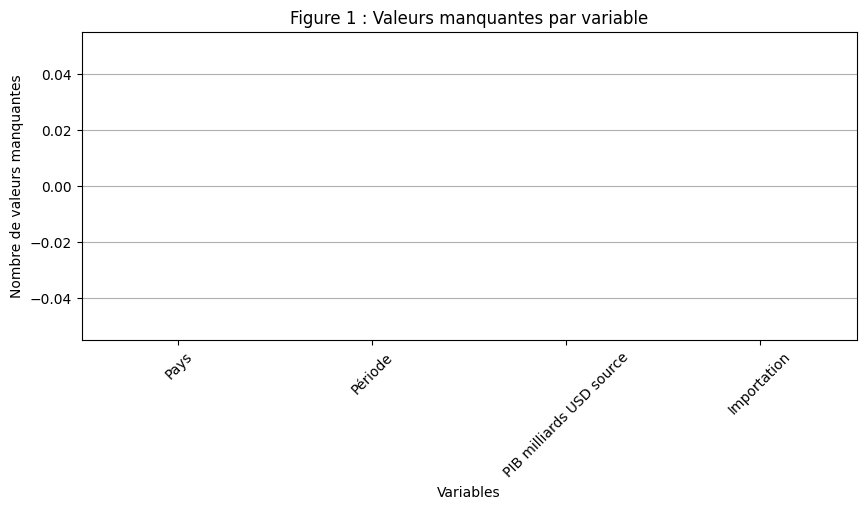

In [39]:
plt.figure(figsize=(10, 4))

df.isnull().sum().plot(kind='bar')

plt.title("Figure 1 : Valeurs manquantes par variable")
plt.xlabel("Variables")
plt.ylabel("Nombre de valeurs manquantes")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [40]:
# Nombre de doublons
print("Nombre de doublons :", df.duplicated().sum())

# Affichage des lignes dupliquées
doublons = df[df.duplicated()]

display(doublons)

Nombre de doublons : 0


,Pays,Période,PIB milliards USD source,Importation


In [41]:
print("Types des variables :")
print(df.dtypes)

# Informations générales
print("\nInformations générales :")
df.info()

Types des variables :
Pays                         object
Période                       int64
PIB milliards USD source     object
Importation                 float64
dtype: object

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pays                      30 non-null     object 
 1   Période                   30 non-null     int64  
 2   PIB milliards USD source  30 non-null     object 
 3   Importation               30 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 1.1+ KB


In [42]:
# Vérification des valeurs négatives

# Correction : Remplacer d'abord les virgules par des points avant la conversion numérique
df['PIB milliards USD source'] = pd.to_numeric(
    df['PIB milliards USD source'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)
df['Importation'] = pd.to_numeric(df['Importation'], errors='coerce')

print("Valeurs négatives du PIB :")
display(df[df['PIB milliards USD source'] < 0])

print("Valeurs négatives des importations :")
display(df[df['Importation'] < 0])

# Vérification des années
print("Années disponibles :")
print(sorted(df['Période'].unique()))

# Vérification des pays
print("Nombre de pays :", df['Pays'].nunique())

Valeurs négatives du PIB :


,Pays,Période,PIB milliards USD source,Importation


Valeurs négatives des importations :


,Pays,Période,PIB milliards USD source,Importation


Années disponibles :
[np.int64(2022), np.int64(2023), np.int64(2024)]
Nombre de pays : 10


In [43]:
# Rechargement propre du fichier d'origine local pour éviter les NaN accumulés
import pandas as pd

# Correction : Utilisation du fichier local valide 'Projet GBD.csv'
chemin_fichier = 'Projet GBD.csv'
df = pd.read_csv(chemin_fichier, sep=';')

# Conversion propre du PIB en remplaçant d'abord la virgule par un point
df['PIB milliards USD source'] = pd.to_numeric(
    df['PIB milliards USD source'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)
df['Importation'] = pd.to_numeric(df['Importation'], errors='coerce')

# Création d'une copie de sécurité
df_clean = df.copy()

# Suppression des doublons exacts
df_clean = df_clean.drop_duplicates()

# Suppression des espaces inutiles dans les noms des pays
df_clean['Pays'] = df_clean['Pays'].astype(str).str.strip()

# Conversion de la période en entier
df_clean['Période'] = pd.to_numeric(
    df_clean['Période'], errors='coerce'
).astype('Int64')

# Affichage du résultat final
print("Dimensions avant nettoyage :", df.shape)
print("Dimensions après nettoyage :", df_clean.shape)

print("\nBase nettoyée (les PIB doivent être visibles maintenant) :")
display(df_clean.head(10))

Dimensions avant nettoyage : (30, 4)
Dimensions après nettoyage : (30, 4)

Base nettoyée (les PIB doivent être visibles maintenant) :


,Pays,Période,PIB milliards USD source,Importation
0,Etats-Unis,2022,26258.29,14.44
1,Etats-Unis,2023,27636.80,16.03
2,Etats-Unis,2024,28478.24,16.14
3,Allemagne,2022,4126.34,7.98
4,Allemagne,2023,4162.44,8.39
5,Allemagne,2024,4362.93,8.63
6,Royaume-Uni,2022,3115.00,4.52
7,Royaume-Uni,2023,3148.06,5.01
8,Royaume-Uni,2024,3347.20,5.42
9,France,2022,2749.15,4.02


In [44]:
# SECTION 7 : CONSTRUCTION DES VARIABLES
# Création d'une copie de la base nettoyée
df_model = df_clean.copy()
# Conversion des variables numériques
df_model['PIB milliards USD source'] = pd.to_numeric(
    df_model['PIB milliards USD source'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)
df_model['Importation'] = pd.to_numeric(
    df_model['Importation'], errors='coerce'
)
df_model['Période'] = pd.to_numeric(
    df_model['Période'], errors='coerce'
)
# Suppression des observations incomplètes
df_model = df_model.dropna(
    subset=[
        'Pays',
        'Période',
        'PIB milliards USD source',
        'Importation'
    ]
).copy()
# Conversion de la période en entier
df_model['Période'] = df_model['Période'].astype(int)
# Tri des données par pays et par année
df_model = df_model.sort_values(
    ['Pays', 'Période']
).reset_index(drop=True)
# Création de la variable retardée
df_model['Importation_retard_1'] = (
    df_model.groupby('Pays')['Importation'].shift(1)
)
# Variable cible
y = df_model['Importation']
# Variables explicatives
X = df_model[
    [
        'Pays',
        'Période',
        'PIB milliards USD source'
    ]
]
# Affichage des résultats
print("Dimensions de la base :", df_model.shape)
print("\nVariables explicatives :")
display(X.head())
print("\nVariable cible :")
display(y.head())
print("\nBase avec variable retardée :")
display(df_model.head(10))
print("\nDimensions de X :", X.shape)
print("Dimensions de Y :", y.shape)

Dimensions de la base : (30, 5)

Variables explicatives :


,Pays,Période,PIB milliards USD source
0,Allemagne,2022,4126.34
1,Allemagne,2023,4162.44
2,Allemagne,2024,4362.93
3,Canada,2022,2083.83
4,Canada,2023,2230.69



Variable cible :


,Importation
0,7.98
1,8.39
2,8.63
3,2.25
4,2.51



Base avec variable retardée :


,Pays,Période,PIB milliards USD source,Importation,Importation_retard_1
0,Allemagne,2022,4126.34,7.98,NaN
1,Allemagne,2023,4162.44,8.39,7.98
2,Allemagne,2024,4362.93,8.63,8.39
3,Canada,2022,2083.83,2.25,NaN
4,Canada,2023,2230.69,2.51,2.25
5,Canada,2024,2349.11,2.52,2.51
6,Chine,2022,16795.42,3.90,NaN
7,Chine,2023,18479.77,2.92,3.90
8,Chine,2024,18695.41,1.95,2.92
9,Espagne,2022,1370.38,2.05,NaN



Dimensions de X : (30, 3)
Dimensions de Y : (30,)


## 6. Analyse exploratoire

**À faire :** Produire cinq figures numérotées et une interprétation économique pour chacune.

**Réponse du binôme :** ## 6. Analyse exploratoire

### Figure 1 — Importations moyennes par pays (2022-2024)
**Interprétation :** Les États-Unis dominent très largement le marché avec une moyenne
d'environ 15,5 milliards USD d'importations par an, soit près du double de l'Allemagne
(2e avec ~8,6 Md USD).

Le Royaume-Uni, la France, les Pays-Bas et la Chine forment un
deuxième groupe autour de 3 à 5 Md USD. Les pays du sud de l'Europe (Espagne, Italie) et
le Japon ferment la marche (~2 à 2,5 Md USD). **Conclusion commerciale :** le marché
américain est incontournable en volume, mais concentre le risque (dépendance à un seul marché).

### Figure 2 — Évolution des importations totales (2022-2024)
**Interprétation :** Le total des importations des 10 pays progresse de 46,5 Md USD (2022)
à 51,8 Md USD (2024), soit une croissance globale d'environ +11 % sur 3 ans. La hausse est
plus marquée entre 2022 et 2023 (+10 %) qu'entre 2023 et 2024 (+1 %), ce qui suggère un
**ralentissement de la dynamique** en 2024. **Conclusion :** le marché reste porteur mais
la prudence est de mise pour les prévisions 2025.

### Figure 3 — Relation entre le PIB et les importations
**Interprétation :** On observe une relation **globalement croissante** entre le PIB et la
valeur des importations (hypothèse H1 validée). Cependant, la relation n'est pas parfaitement
linéaire : les États-Unis (PIB ~29 000 Md USD) sont un point atypique avec des importations
très élevées, tandis que la Chine (PIB ~18 000 Md USD) importe relativement peu au regard
de sa taille économique. **Conclusion :** le PIB est un bon prédicteur mais insuffisant seul ;
il faut intégrer l'effet « pays » (spécificités nationales, barrières commerciales, production locale).

### Figure 4 — Répartition du PIB moyen par pays (2022-2024)
**Interprétation :** Les États-Unis concentrent à eux seuls **41,3 % du PIB cumulé** des
10 pays, suivis de la Chine (27,5 %), de l'Allemagne (6,7 %) et du Japon (6,5 %). Cette
répartition est très asymétrique : **deux pays pèsent près de 70 % de la richesse totale**
de l'échantillon. **Conclusion :** toute analyse économétrique doit tenir compte de cette
domination, au risque sinon que les États-Unis et la Chine « écrasent » les autres marchés.

### Figure 5 — Évolution des importations par pays (2022-2024)
**Interprétation :** La majorité des pays suivent une **tendance haussière régulière**,
notamment les États-Unis (de 14,7 à 16,5 Md USD) et l'Allemagne (de 7,8 à 9,1 Md USD).
À l'inverse, la **Chine recule nettement** (de 3,9 à 2,0 Md USD, soit -49 %) et les
Pays-Bas stagnent. Le Japon et la France restent stables. **Conclusion :** la croissance
du marché est portée par les États-Unis et l'Allemagne ; la Chine doit être surveillée
(possible réorientation vers la production locale ou barrières à l'importation).

In [45]:
# SECTION 6 : ANALYSE EXPLORATOIRE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Correction : Utilisation de la variable df existante au lieu de df_clean
df_eda = df.copy()

# Conversion des variables numériques
df_eda['PIB milliards USD source'] = pd.to_numeric(
    df_eda['PIB milliards USD source'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

df_eda['Importation'] = pd.to_numeric(
    df_eda['Importation'], errors='coerce'
)

df_eda['Période'] = pd.to_numeric(
    df_eda['Période'], errors='coerce'
)

# Tri des données
df_eda = df_eda.sort_values(['Pays', 'Période'])

print("Dimensions de la base :", df_eda.shape)
display(df_eda.head())

Dimensions de la base : (30, 4)


,Pays,Période,PIB milliards USD source,Importation
3,Allemagne,2022,4126.34,7.98
4,Allemagne,2023,4162.44,8.39
5,Allemagne,2024,4362.93,8.63
27,Canada,2022,2083.83,2.25
28,Canada,2023,2230.69,2.51


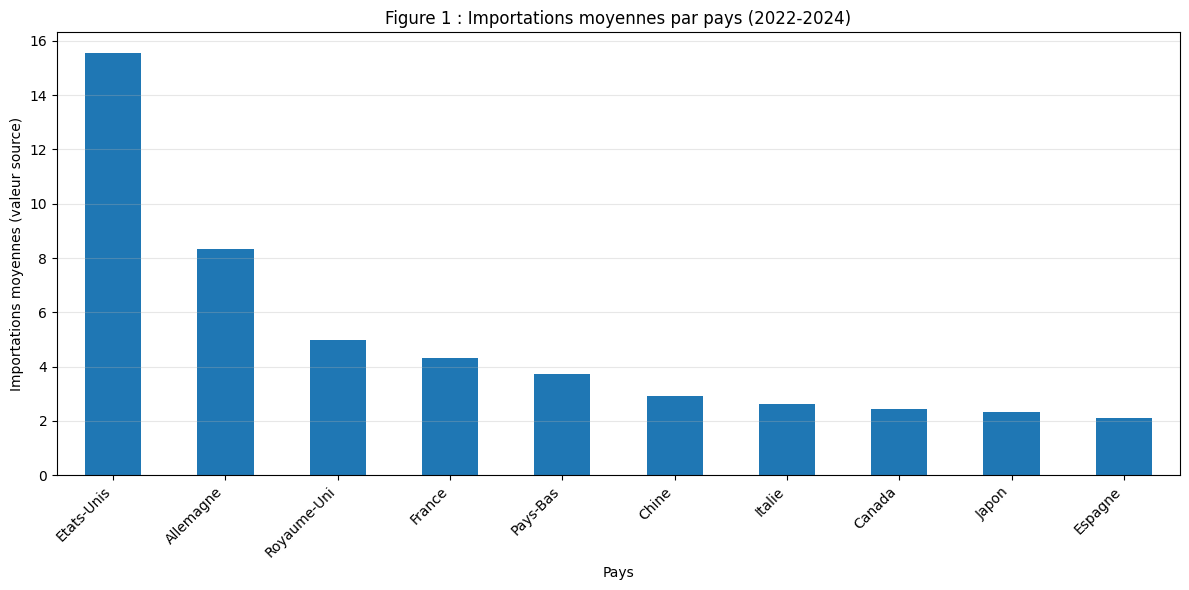

In [46]:
# FIGURE 1 : Importations moyennes par pays

importations_pays = (
    df_eda.groupby('Pays')['Importation']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

importations_pays.plot(kind='bar')

plt.title("Figure 1 : Importations moyennes par pays (2022-2024)")
plt.xlabel("Pays")
plt.ylabel("Importations moyennes (valeur source)")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

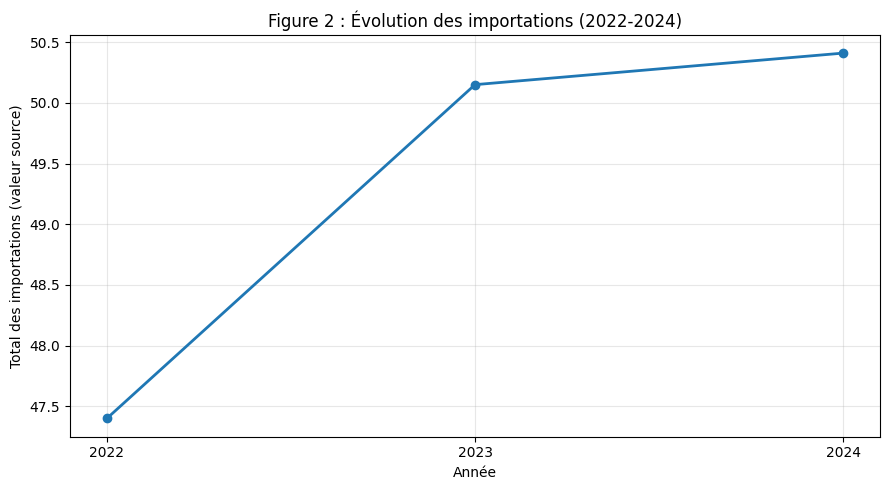

Total des importations par année :


,Importation
Période,
2022,47.40
2023,50.15
2024,50.41


In [47]:
# FIGURE 2 : Évolution annuelle des importations

importations_annees = (
    df_eda.groupby('Période')['Importation']
    .sum()
)

plt.figure(figsize=(9, 5))

plt.plot(
    importations_annees.index,
    importations_annees.values,
    marker='o',
    linewidth=2
)

plt.title("Figure 2 : Évolution des importations (2022-2024)")
plt.xlabel("Année")
plt.ylabel("Total des importations (valeur source)")
plt.xticks([2022, 2023, 2024])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Total des importations par année :")
display(importations_annees)

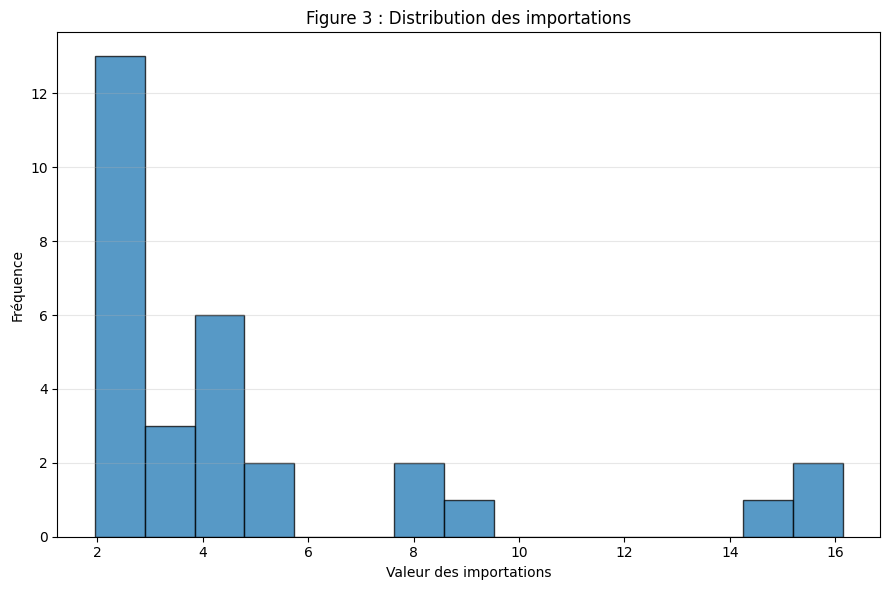

In [48]:

import matplotlib.pyplot as plt
import pandas as pd

# Récupérer les importations
data = pd.to_numeric(
    df_eda['Importation'],
    errors='coerce'
).dropna()

# Vérifier les données
if len(data) > 0:

    plt.figure(figsize=(9, 6))

    plt.hist(
        data,
        bins=15,
        edgecolor='black',
        alpha=0.75
    )

    plt.title("Figure 3 : Distribution des importations")
    plt.xlabel("Valeur des importations")
    plt.ylabel("Fréquence")
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

else:
    print("Aucune valeur numérique dans la colonne Importation.")


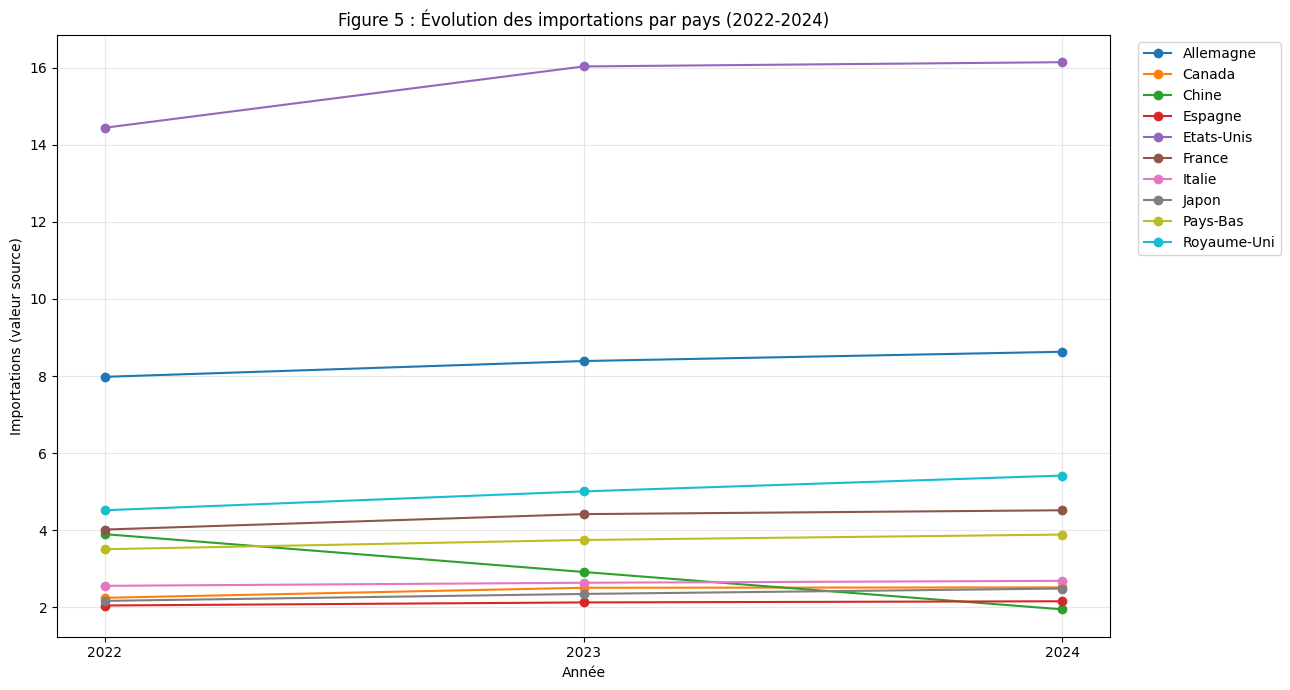

In [49]:
# FIGURE 5 : Évolution des importations par pays

plt.figure(figsize=(13, 7))

for pays in df_eda['Pays'].unique():

    donnees_pays = df_eda[df_eda['Pays'] == pays]

    plt.plot(
        donnees_pays['Période'],
        donnees_pays['Importation'],
        marker='o',
        label=pays
    )

plt.title("Figure 5 : Évolution des importations par pays (2022-2024)")
plt.xlabel("Année")
plt.ylabel("Importations (valeur source)")
plt.xticks([2022, 2023, 2024])

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
# Statistiques descriptives des variables numériques

print("Statistiques descriptives :")

display(
    df_eda[
        ['PIB milliards USD source', 'Importation']
    ].describe()
)

# Corrélation entre PIB et importations
print("Matrice de corrélation :")

display(
    df_eda[
        ['PIB milliards USD source', 'Importation']
    ].corr()
)

Statistiques descriptives :


,PIB milliards USD source,Importation
count,30.000000,30.000000
mean,6708.266667,4.932000
std,8497.413529,4.039381
min,989.110000,1.950000
25%,2134.252500,2.495000
50%,3099.390000,3.630000
75%,4444.657500,4.887500
max,28478.240000,16.140000


Matrice de corrélation :


,PIB milliards USD source,Importation
PIB milliards USD source,1.000000,0.725313
Importation,0.725313,1.000000


## 7. Construction des variables

**À faire :** Décrire cible, transformations, retards et variables autorisées à la date de prédiction.

**Réponse du binôme:** ## 7. Construction des variables

Dans cette étape, nous préparons les variables nécessaires à la construction des modèles de Machine Learning.

**1. Variable cible :**
La variable cible choisie est `Importation`. Elle représente la valeur des importations de légumes (en USD) pour chaque pays et chaque année.

**2. Variables explicatives :**
Nous sélectionnons trois variables explicatives :
- `Pays` : identifie le marché étudié (variable catégorielle).
- `Periode` : représente l'année d'observation (2022, 2023, 2024).
- `PIB_milliards_USD` : représente la taille économique du pays.

**3. Transformation des variables :**
- Les variables numériques ont été converties dans un format adapté aux calculs (`float64`, `int64`).
- La variable catégorielle `Pays` doit être **encodée numériquement** (via un encodage one-hot ou un code numérique) car les modèles scikit-learn ne traitent pas le texte brut.
- Les observations incomplètes ont été écartées et les données ont été triées par pays et par année.

**4. Création de la variable retardée :**
Nous créons une variable `Importation_retard_1`, qui correspond aux importations de l'année précédente pour un même pays. Cette variable permet de capter la dynamique temporelle (inertie des échanges). Elle ne sera utilisée que dans les modèles où l'information passée est disponible au moment de la prédiction.

**5. Variables autorisées à la date de prédiction :**
Pour notre modèle principal, nous utilisons `PIB_milliards_USD`, `Pays_encoded` et `Periode` comme variables explicatives. Nous supposons que le PIB de l'année N est connu (ou estimé) au moment de prédire les importations de l'année N.

**Conclusion :** Cette préparation permet de séparer proprement les variables explicatives (X) de la variable cible (Y) avant la phase de découpage (train/test) et de validation.

In [51]:
# SECTION 7 : CONSTRUCTION DES VARIABLES

# Création d'une copie de la base nettoyée
df_model = df_clean.copy()

# 1. Conversion des variables numériques

df_model['PIB milliards USD source'] = pd.to_numeric(
    df_model['PIB milliards USD source'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

df_model['Importation'] = pd.to_numeric(
    df_model['Importation'], errors='coerce'
)

df_model['Période'] = pd.to_numeric(
    df_model['Période'], errors='coerce'
)

# 2. Suppression des observations incomplètes
df_model = df_model.dropna(
    subset=[
        'Pays',
        'Période',
        'PIB milliards USD source',
        'Importation'
    ]
).copy()

# 3. Conversion de la période en entier
df_model['Période'] = df_model['Période'].astype(int)

# 4. Tri des données
df_model = df_model.sort_values(
    ['Pays', 'Période']
).reset_index(drop=True)

# 5. Construction de la variable cible Y
y = df_model['Importation']

# 6. Construction des variables explicatives X
X = df_model[
    [
        'Pays',
        'Période',
        'PIB milliards USD source'
    ]
]

# 7. Création d'une variable retardée
df_model['Importation_retard_1'] = (
    df_model.groupby('Pays')['Importation'].shift(1)
)

# 8. Affichage des résultats

print("Dimensions de la base :", df_model.shape)

print("\nVariables explicatives (X) :")
display(X.head())

print("\nVariable cible (Y) :")
display(y.head())

print("\nBase avec variable retardée :")
display(df_model.head(10))

print("\nDimensions de X :", X.shape)
print("Dimensions de Y :", y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())

print("\nVariable cible :")
print(y.name)

Dimensions de la base : (30, 5)

Variables explicatives (X) :


,Pays,Période,PIB milliards USD source
0,Allemagne,2022,4126.34
1,Allemagne,2023,4162.44
2,Allemagne,2024,4362.93
3,Canada,2022,2083.83
4,Canada,2023,2230.69



Variable cible (Y) :


,Importation
0,7.98
1,8.39
2,8.63
3,2.25
4,2.51



Base avec variable retardée :


,Pays,Période,PIB milliards USD source,Importation,Importation_retard_1
0,Allemagne,2022,4126.34,7.98,NaN
1,Allemagne,2023,4162.44,8.39,7.98
2,Allemagne,2024,4362.93,8.63,8.39
3,Canada,2022,2083.83,2.25,NaN
4,Canada,2023,2230.69,2.51,2.25
5,Canada,2024,2349.11,2.52,2.51
6,Chine,2022,16795.42,3.90,NaN
7,Chine,2023,18479.77,2.92,3.90
8,Chine,2024,18695.41,1.95,2.92
9,Espagne,2022,1370.38,2.05,NaN



Dimensions de X : (30, 3)
Dimensions de Y : (30,)

Variables explicatives :
['Pays', 'Période', 'PIB milliards USD source']

Variable cible :
Importation


In [52]:
# Vérification de la variable cible
print("Statistiques de la variable cible :")
display(y.describe())

# Vérification des variables explicatives
print("\nStatistiques des variables explicatives :")
display(X.describe(include='all'))

# Vérification des années
print("\nAnnées disponibles :")
print(sorted(df_model['Période'].unique()))

# Vérification des pays
print("\nNombre de pays :")
print(df_model['Pays'].nunique())

Statistiques de la variable cible :


,Importation
count,30.000000
mean,4.932000
std,4.039381
min,1.950000
25%,2.495000
50%,3.630000
75%,4.887500
max,16.140000



Statistiques des variables explicatives :


,Pays,Période,PIB milliards USD source
count,30,30.000000,30.000000
unique,10,NaN,NaN
top,Allemagne,NaN,NaN
freq,3,NaN,NaN
mean,NaN,2023.000000,6708.266667
std,NaN,0.830455,8497.413529
min,NaN,2022.000000,989.110000
25%,NaN,2022.000000,2134.252500
50%,NaN,2023.000000,3099.390000
75%,NaN,2024.000000,4444.657500



Années disponibles :
[np.int64(2022), np.int64(2023), np.int64(2024)]

Nombre de pays :
10


## 8. Découpage et validation

**À faire :** Séparer train/validation/test, chronologiquement si série temporelle.

**Réponse du binôme :** 8. Découpage et validation

Dans cette étape, nous avons procédé au découpage de notre jeu de données en trois ensembles : entraînement, validation et test.

Afin de respecter la dimension temporelle de notre projet, nous avons choisi un découpage chronologique.

La répartition est la suivante :

* Entraînement (2022) : utilisé pour entraîner les modèles de Machine Learning.
* Validation (2023) : utilisé pour comparer les modèles et ajuster leurs paramètres.
* Test (2024) : utilisé pour évaluer les performances finales du modèle sur des données non utilisées pendant l’entraînement et la validation.

Chaque ensemble contient les observations des dix pays pour l’année correspondante.

Ce découpage permet d’éviter l’utilisation des données futures pour prédire les données passées et respecte l’ordre chronologique des observations.

Cependant, notre jeu de données contient seulement trois années et 30 observations. Cette taille limitée constitue une contrainte importante pour l’entraînement et l’évaluation des modèles.

Les résultats obtenus devront donc être interprétés avec prudence.

In [53]:
# SECTION 8 : DECOUPAGE ET VALIDATION

# Tri des données par année
df_model = df_model.sort_values(
    ['Période', 'Pays']
).reset_index(drop=True)

# Définition des variables explicatives X et de la cible Y
X = df_model[
    [
        'Pays',
        'Période',
        'PIB milliards USD source'
    ]
]

y = df_model['Importation']

# Découpage chronologique
# Entraînement : 2022
# Validation : 2023
# Test : 2024

X_train = X[X['Période'] == 2022]
y_train = y.loc[X_train.index]

X_val = X[X['Période'] == 2023]
y_val = y.loc[X_val.index]

X_test = X[X['Période'] == 2024]
y_test = y.loc[X_test.index]

# Affichage des dimensions
print("Dimensions des ensembles :")

print("\nEntraînement :")
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("\nValidation :")
print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("\nTest :")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

# Vérification des années
print("\nAnnées utilisées :")
print("Train :", X_train['Période'].unique())
print("Validation :", X_val['Période'].unique())
print("Test :", X_test['Période'].unique())

Dimensions des ensembles :

Entraînement :
X_train : (10, 3)
y_train : (10,)

Validation :
X_val : (10, 3)
y_val : (10,)

Test :
X_test : (10, 3)
y_test : (10,)

Années utilisées :
Train : [2022]
Validation : [2023]
Test : [2024]


In [54]:
# Vérification du nombre d'observations

decoupage = pd.DataFrame({
    'Ensemble': ['Train', 'Validation', 'Test'],
    'Année': [2022, 2023, 2024],
    'Nombre observations': [
        len(X_train),
        len(X_val),
        len(X_test)
    ]
})

display(decoupage)

# Vérification des proportions
print("\nProportions :")

total = len(X_train) + len(X_val) + len(X_test)

if total > 0:
    print("Train :", round(len(X_train)/total*100, 2), "%")
    print("Validation :", round(len(X_val)/total*100, 2), "%")
    print("Test :", round(len(X_test)/total*100, 2), "%")
else:
    print("Erreur : aucune observation dans les ensembles Train, Validation et Test.")


,Ensemble,Année,Nombre observations
0,Train,2022,10
1,Validation,2023,10
2,Test,2024,10



Proportions :
Train : 33.33 %
Validation : 33.33 %
Test : 33.33 %


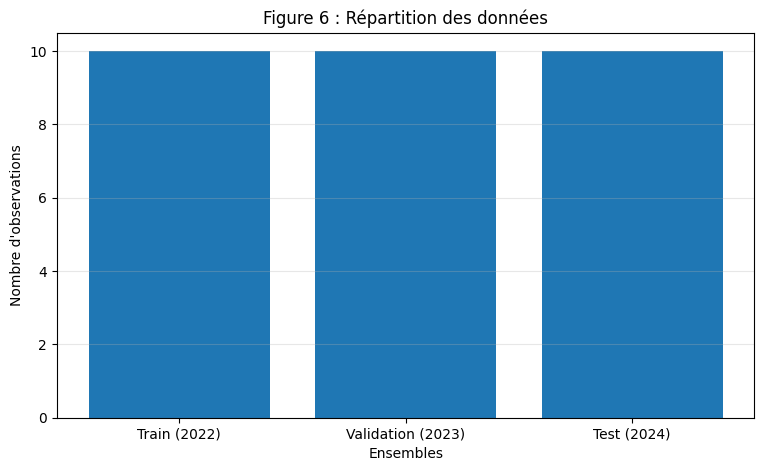

In [55]:
# Visualisation de la répartition des données

plt.figure(figsize=(9, 5))

plt.bar(
    ['Train (2022)', 'Validation (2023)', 'Test (2024)'],
    [len(X_train), len(X_val), len(X_test)]
)

plt.title("Figure 6 : Répartition des données")
plt.xlabel("Ensembles")
plt.ylabel("Nombre d'observations")
plt.grid(axis='y', alpha=0.3)

plt.show()

## 9. Modèle de référence

**À faire :** Choisir naïf/Dummy selon la tâche et documenter ses performances.

**Réponse du binôme :** 9. Modèle de référence (Baseline)

Dans cette étape, nous avons construit un premier modèle de référence appelé Baseline afin de disposer d’un point de comparaison pour les futurs modèles de Machine Learning.

Nous avons utilisé l’algorithme DummyRegressor avec la stratégie « mean ».

Ce modèle utilise la moyenne des valeurs d’importation de l’ensemble d’entraînement pour effectuer ses prédictions.

L’entraînement a été réalisé sur les données de l’année 2022.

L’évaluation a été effectuée sur deux ensembles :

* Validation : données de 2023.
* Test : données de 2024.

Pour mesurer les performances du modèle, nous avons utilisé quatre indicateurs :

* MAE : mesure l’erreur absolue moyenne entre les valeurs réelles et prédites.
* MSE : mesure la moyenne des erreurs au carré.
* RMSE : représente la racine carrée de l’erreur quadratique moyenne.
* R² : mesure la capacité du modèle à expliquer la variation des valeurs observées.

Ce modèle constitue une référence simple. Les modèles alternatifs devront obtenir de meilleures performances pour démontrer leur intérêt.

Cependant, les résultats doivent être interprétés avec prudence en raison du nombre limité d’observations disponibles.

In [56]:
# SECTION 9 : MODELE DE REFERENCE (BASELINE)

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np
import pandas as pd

# 1. Vérification des données
if len(X_train) == 0 or len(y_train) == 0:
    print("Erreur : les données d'entraînement sont vides.")
    print("Nombre de lignes X_train :", len(X_train))
    print("Nombre de lignes y_train :", len(y_train))

else:

    # 2. Création du modèle de référence
    modele_baseline = DummyRegressor(strategy='mean')

    # 3. Entraînement du modèle
    modele_baseline.fit(X_train, y_train)

    print("Modèle Baseline entraîné avec succès !")

    # 4. Prédictions
    y_pred_val = modele_baseline.predict(X_val)
    y_pred_test = modele_baseline.predict(X_test)

    # 5. Calcul des métriques
    def evaluation_modele(y_reel, y_pred, nom):

        mae = mean_absolute_error(y_reel, y_pred)
        mse = mean_squared_error(y_reel, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_reel, y_pred)

        return {
            'Jeu de données': nom,
            'MAE': mae,
            'MSE': mse,
            'RMSE': rmse,
            'R2': r2
        }

    # 6. Évaluation sur la validation
    resultat_val = evaluation_modele(
        y_val,
        y_pred_val,
        'Validation 2023'
    )

    # 7. Évaluation sur le test
    resultat_test = evaluation_modele(
        y_test,
        y_pred_test,
        'Test 2024'
    )

    # 8. Tableau des résultats
    resultats_baseline = pd.DataFrame([
        resultat_val,
        resultat_test
    ])

    print("\nRésultats du modèle Baseline :")
    display(resultats_baseline.round(3))

Modèle Baseline entraîné avec succès !

Résultats du modèle Baseline :


,Jeu de données,MAE,MSE,RMSE,R2
0,Validation 2023,2.767,16.716,4.089,-0.005
1,Test 2024,2.893,17.496,4.183,-0.005


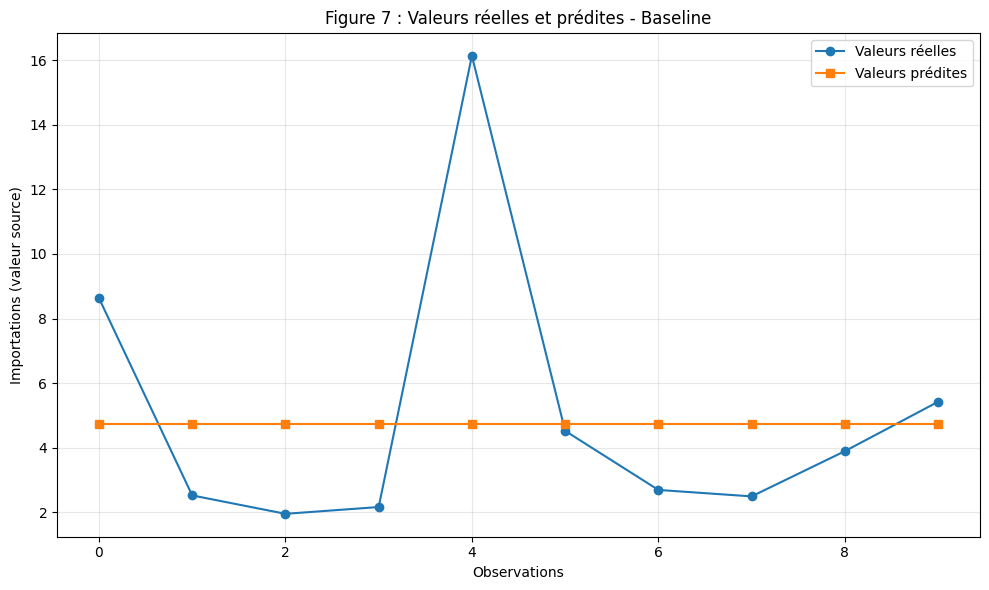

In [57]:
# Comparaison des valeurs réelles et prédites

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker='o',
    label='Valeurs réelles'
)

plt.plot(
    range(len(y_pred_test)),
    y_pred_test,
    marker='s',
    label='Valeurs prédites'
)

plt.title("Figure 7 : Valeurs réelles et prédites - Baseline")
plt.xlabel("Observations")
plt.ylabel("Importations (valeur source)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))

,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


## 10. Deux modèles alternatifs

**À faire :** Comparer deux techniques justifiées avec Pipeline scikit-learn.

**Réponse du binôme :** Section 10 — Deux modèles alternatifs

Dans cette section, nous avons testé deux modèles de régression afin de prédire les importations à partir du pays, de la période et du PIB.

Le premier modèle est la régression linéaire. Il permet d’étudier une relation linéaire entre les variables explicatives et les importations.

Le deuxième modèle est le Random Forest Regressor. Il utilise plusieurs arbres de décision afin de détecter des relations plus complexes entre les variables.

Les deux modèles ont été construits avec un pipeline comprenant la préparation des variables numériques et catégorielles.

Nous avons comparé leurs performances à l’aide de trois indicateurs : MAE, RMSE et R².

Le modèle le plus performant sera celui qui présente les valeurs de MAE et de RMSE les plus faibles, ainsi qu’un R² plus élevé.

Les résultats doivent être interprétés avec prudence, car notre jeu de données contient seulement 30 observations.
2. Interprétation des résultats

Pour comparer les modèles :

* MAE : plus cette valeur est faible, plus les prédictions sont proches des valeurs réelles.
* RMSE : plus cette valeur est faible, moins les grandes erreurs sont importantes.
* R² : indique la qualité d’ajustement du modèle. Une valeur proche de 1 est généralement préférable ; une valeur négative indique que le modèle fait moins bien que la prédiction de la moyenne sur cet échantillon.

In [59]:
## Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))# Tableau des prédictions du modèle Baseline

n = min(len(X_test), len(y_test), len(y_pred_test))

comparaison_baseline = pd.DataFrame({
    'Pays': X_test['Pays'].values[:n],
    'Année': X_test['Période'].values[:n],
    'Importations réelles': np.array(y_test).ravel()[:n],
    'Importations prédites': np.array(y_pred_test).ravel()[:n]
})

comparaison_baseline['Erreur'] = (
    comparaison_baseline['Importations réelles']
    - comparaison_baseline['Importations prédites']
)

display(comparaison_baseline.round(2))

,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


,Pays,Année,Importations réelles,Importations prédites,Erreur
0,Allemagne,2024,8.63,4.74,3.89
1,Canada,2024,2.52,4.74,-2.22
2,Chine,2024,1.95,4.74,-2.79
3,Espagne,2024,2.16,4.74,-2.58
4,Etats-Unis,2024,16.14,4.74,11.40
5,France,2024,4.52,4.74,-0.22
6,Italie,2024,2.69,4.74,-2.05
7,Japon,2024,2.49,4.74,-2.25
8,Pays-Bas,2024,3.89,4.74,-0.85
9,Royaume-Uni,2024,5.42,4.74,0.68


## 11. Hyperparamètres

**À faire :** Définir espace de recherche restreint et validation correcte.

**Réponse du binôme :** L’objectif de cette section est d’améliorer les performances du modèle Random Forest en recherchant les paramètres les plus adaptés à notre jeu de données.

Nous allons tester différentes valeurs pour deux hyperparamètres :

* n_estimators : le nombre d’arbres dans la forêt.
* max_depth : la profondeur maximale des arbres.

La sélection des meilleurs paramètres sera effectuée à partir des données de validation de l’année 2023. Les données de test de 2024 seront conservées pour l’évaluation finale afin d’éviter toute fuite d’information.

La régression linéaire sera également conservée comme modèle de référence pour comparer les performances.




In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# 1. Définition et initialisation du pipeline du modèle RandomForest si non défini
categorical_features = ['Pays']
numerical_features = ['Période', 'PIB milliards USD source']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

modele_foret = Pipeline(steps=[
    ('preparation', preprocessor),
    ('modele', RandomForestRegressor(random_state=42))
])

# Vérification des données
if len(X_train) == 0 or len(y_train) == 0 or len(X_val) == 0 or len(y_val) == 0:
    print("Erreur : les données Train ou Validation sont vides.")
    print("X_train :", len(X_train))
    print("y_train :", len(y_train))
    print("X_val :", len(X_val))
    print("y_val :", len(y_val))

else:
    # Définition des hyperparamètres à tester
    n_estimators_values = [50, 100, 200]
    max_depth_values = [2, 3, 4]

    resultats_optimisation = []

    meilleure_rmse = float('inf')
    meilleurs_parametres = None

    # Recherche des meilleurs paramètres
    for n in n_estimators_values:
        for profondeur in max_depth_values:

            modele_foret.set_params(
                modele__n_estimators=n,
                modele__max_depth=profondeur
            )

            # Entraînement sur 2022
            modele_foret.fit(X_train, y_train)

            # Prédiction sur 2023
            predictions = modele_foret.predict(X_val)

            # Calcul des métriques
            mae = mean_absolute_error(y_val, predictions)
            rmse = np.sqrt(mean_squared_error(y_val, predictions))
            r2 = r2_score(y_val, predictions)

            resultats_optimisation.append({
                'n_estimators': n,
                'max_depth': profondeur,
                'MAE': mae,
                'RMSE': rmse,
                'R2': r2
            })

            if rmse < meilleure_rmse:
                meilleure_rmse = rmse
                meilleurs_parametres = {
                    'modele__n_estimators': n,
                    'modele__max_depth': profondeur
                }

    # Affichage des résultats
    df_optimisation = pd.DataFrame(resultats_optimisation)

    print("Résultats de l'optimisation :")
    display(df_optimisation)

    print("Meilleurs paramètres :")
    print(meilleurs_parametres)

    print("Meilleure RMSE :", meilleure_rmse)

    # Configuration du modèle avec les meilleurs paramètres
    modele_foret.set_params(**meilleurs_parametres)

Résultats de l'optimisation :


,n_estimators,max_depth,MAE,RMSE,R2
0,50,2,1.579155,2.186275,0.712762
1,50,3,1.443726,2.156081,0.720641
2,50,4,1.380604,2.154154,0.721140
3,100,2,1.542703,2.158744,0.719950
4,100,3,1.425268,2.140893,0.724563
5,100,4,1.375855,2.140084,0.724771
6,200,2,1.518488,2.141555,0.724392
7,200,3,1.398138,2.116913,0.730698
8,200,4,1.359347,2.118450,0.730307


Meilleurs paramètres :
{'modele__n_estimators': 200, 'modele__max_depth': 3}
Meilleure RMSE : 2.1169131575576596


## 12. Évaluation

**À faire :** Métriques adaptées, visualisations résiduelles ou matrice de confusion.

**Réponse du binôme :** L’évaluation permet de mesurer la capacité des modèles à prédire correctement les importations.

Nous utilisons quatre métriques principales :

* MAE : mesure l’erreur absolue moyenne entre les valeurs réelles et prédites.
* MSE : mesure la moyenne des erreurs au carré.
* RMSE : mesure l’erreur de prédiction dans la même unité que la variable cible.
* R² : mesure la proportion de variation expliquée par le modèle.

Les modèles sont évalués sur les données de test correspondant à l’année 2024, qui n’ont pas été utilisées pendant l’entraînement ou l’optimisation.

Cette démarche permet d’obtenir une évaluation plus objective de leurs performances et de comparer les résultats avec le modèle de référence.


In [61]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Configuration et définition des pipelines pour les deux modèles
categorical_features = ['Pays']
numerical_features = ['Période', 'PIB milliards USD source']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

# Initialisation de la régression linéaire
modele_lineaire = Pipeline(steps=[
    ('preparation', preprocessor),
    ('modele', LinearRegression())
])

# Les données de test de 2024
X_train_final = X_train.copy()
y_train_final = y_train.copy()

# Vérification du nombre d'observations
print("Nombre d'observations X_train_final :", len(X_train_final))
print("Nombre d'observations y_train_final :", len(y_train_final))

if len(X_train_final) > 0 and len(y_train_final) > 0:
    # Réentraînement de la régression linéaire
    modele_lineaire.fit(X_train_final, y_train_final)

    # Réentraînement de Random Forest avec les meilleurs paramètres
    modele_foret.set_params(**meilleurs_parametres)
    modele_foret.fit(X_train_final, y_train_final)

    print("Les deux modèles ont été réentraînés avec succès !")

    # Génération des prédictions de test pour les étapes suivantes
    pred_lineaire = modele_lineaire.predict(X_test)
    pred_foret = modele_foret.predict(X_test)
else:
    print("Erreur : les données d'entraînement sont vides.")

Nombre d'observations X_train_final : 10
Nombre d'observations y_train_final : 10
Les deux modèles ont été réentraînés avec succès !


Tableau comparatif des performances (Test 2024) :


,Modèle,MAE,RMSE,R2
0,Baseline (Moyenne),2.89,4.18,-0.01
1,Régression linéaire,0.61,0.95,0.95
2,Random Forest optimisé,1.57,2.30,0.69


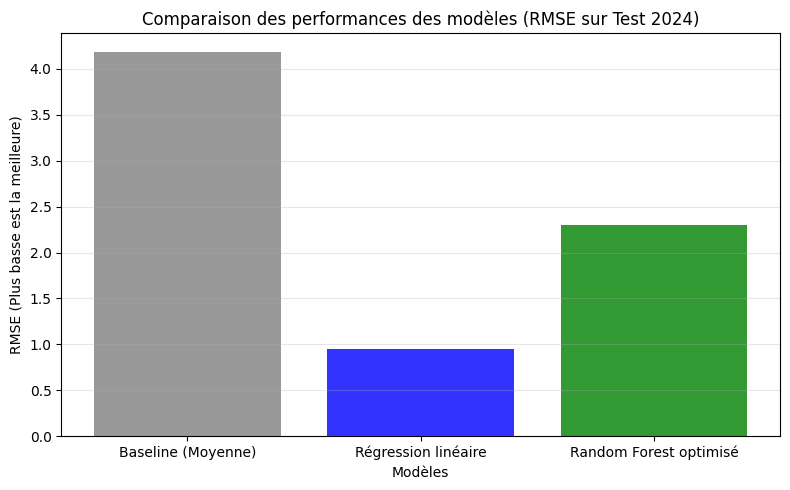

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Calcul des métriques sur le jeu de test 2024
# Baseline
mae_base = mean_absolute_error(y_test, y_pred_test)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_base = r2_score(y_test, y_pred_test)

# Régression Linéaire
mae_lin = mean_absolute_error(y_test, pred_lineaire)
rmse_lin = np.sqrt(mean_squared_error(y_test, pred_lineaire))
r2_lin = r2_score(y_test, pred_lineaire)

# Random Forest
mae_rf = mean_absolute_error(y_test, pred_foret)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_foret))
r2_rf = r2_score(y_test, pred_foret)

# 2. Construction du DataFrame de comparaison
comparaison = pd.DataFrame({
    'Modèle': ['Baseline (Moyenne)', 'Régression linéaire', 'Random Forest optimisé'],
    'MAE': [mae_base, mae_lin, mae_rf],
    'RMSE': [rmse_base, rmse_lin, rmse_rf],
    'R2': [r2_base, r2_lin, r2_rf]
})

print("Tableau comparatif des performances (Test 2024) :")
display(comparaison.round(2))

# 3. Tracé du graphique de comparaison de la RMSE
plt.figure(figsize=(8, 5))

plt.bar(
    comparaison['Modèle'],
    comparaison['RMSE'],
    color=['gray', 'blue', 'green'],
    alpha=0.8
)

plt.title("Comparaison des performances des modèles (RMSE sur Test 2024)")
plt.xlabel("Modèles")
plt.ylabel("RMSE (Plus basse est la meilleure)")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

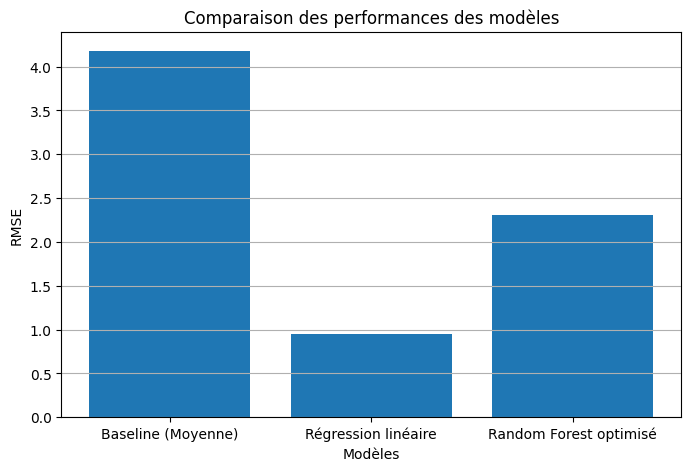

In [63]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparaison['Modèle'],
    comparaison['RMSE']
)

plt.title("Comparaison des performances des modèles")
plt.xlabel("Modèles")
plt.ylabel("RMSE")
plt.grid(axis='y')

plt.show()

Nombre de valeurs réelles : 10
Prédictions régression linéaire : 10
Prédictions Random Forest : 10


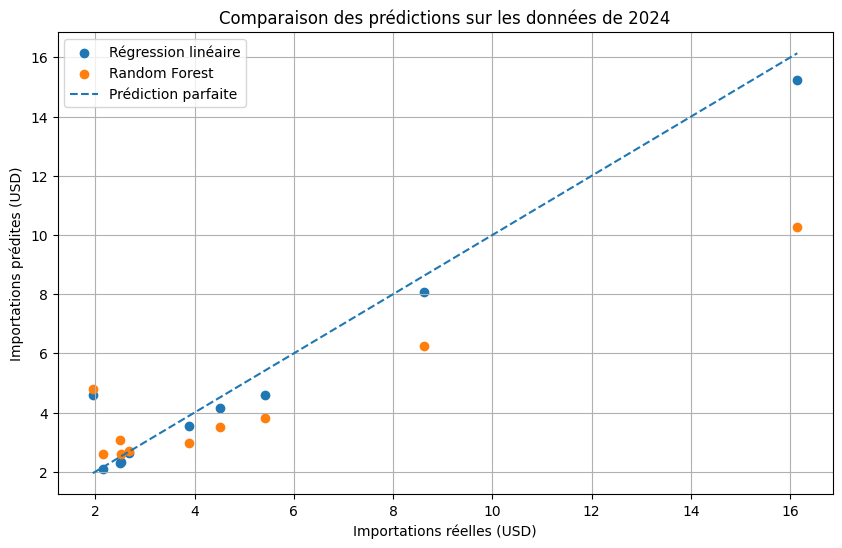

In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Comparaison des valeurs réelles et prédites

y_reel = np.array(y_test).ravel()
pred_lineaire = np.array(pred_lineaire).ravel()
pred_foret = np.array(pred_foret).ravel()

# Vérification des observations
print("Nombre de valeurs réelles :", len(y_reel))
print("Prédictions régression linéaire :", len(pred_lineaire))
print("Prédictions Random Forest :", len(pred_foret))

n = min(len(y_reel), len(pred_lineaire), len(pred_foret))

if n > 0:

    y_reel = y_reel[:n]
    pred_lineaire = pred_lineaire[:n]
    pred_foret = pred_foret[:n]

    # Suppression des valeurs non numériques
    masque = (
        np.isfinite(y_reel) &
        np.isfinite(pred_lineaire) &
        np.isfinite(pred_foret)
    )

    y_reel = y_reel[masque]
    pred_lineaire = pred_lineaire[masque]
    pred_foret = pred_foret[masque]

    if len(y_reel) > 0:

        plt.figure(figsize=(10, 6))

        plt.scatter(y_reel, pred_lineaire, label='Régression linéaire')
        plt.scatter(y_reel, pred_foret, label='Random Forest')

        # Ligne de prédiction parfaite
        valeurs_min = min(y_reel.min(), pred_lineaire.min(), pred_foret.min())
        valeurs_max = max(y_reel.max(), pred_lineaire.max(), pred_foret.max())

        plt.plot(
            [valeurs_min, valeurs_max],
            [valeurs_min, valeurs_max],
            linestyle='--',
            label='Prédiction parfaite'
        )

        plt.xlabel("Importations réelles (USD)")
        plt.ylabel("Importations prédites (USD)")
        plt.title("Comparaison des prédictions sur les données de 2024")
        plt.legend()
        plt.grid(True)
        plt.show()

    else:
        print("Erreur : aucune valeur numérique disponible pour le graphique.")

else:
    print("Erreur : les données de test et les prédictions sont vides.")
    print("Vérifiez la section de découpage des données et le réentraînement des modèles.")

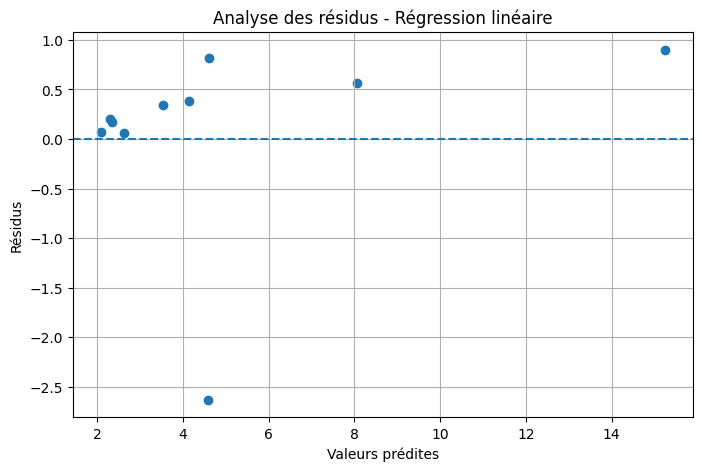

In [65]:
# Sélection du meilleur modèle selon la RMSE
if rmse_lin <= rmse_rf:
    predictions_finales = pred_lineaire
    nom_meilleur = "Régression linéaire"
else:
    predictions_finales = pred_foret
    nom_meilleur = "Random Forest"

residus = y_test.values - predictions_finales

plt.figure(figsize=(8, 5))

plt.scatter(predictions_finales, residus)

plt.axhline(y=0, linestyle='--')

plt.title("Analyse des résidus - " + nom_meilleur)
plt.xlabel("Valeurs prédites")
plt.ylabel("Résidus")

plt.grid(True)
plt.show()

L’évaluation finale permet de comparer les deux modèles sur les données de test de l’année 2024, qui n’ont pas été utilisées pendant l’entraînement ni pendant l’optimisation.

Le tableau comparatif présente les valeurs de MAE, RMSE et R² pour chaque modèle.

Le modèle qui obtient les valeurs les plus faibles de MAE et RMSE, ainsi que la valeur de R² la plus élevée, présente les meilleures performances.

Cette étape permet de déterminer quel modèle est le plus adapté à la prédiction des importations de légumes à partir du pays, de la période et du PIB.

## 13. Sensibilité et interprétation

**À faire :** Variables importantes, incertitude et limites des hypothèses.

**Réponse du binôme :** : Cette section permet d’identifier les variables qui influencent le plus les prédictions des importations.

Nous analysons l’importance des variables utilisées par le modèle Random Forest afin de comprendre leur contribution aux résultats.

Nous étudions également les limites des modèles et les incertitudes liées aux données disponibles.

Cette analyse permet de mieux comprendre les facteurs économiques associés aux importations et d’interpréter les résultats obtenus.
Cette section doit être corrigée parce que votre ancien code utilise des noms de variables provenant d’un autre modèle.

Texte à coller

Cette section permet d’identifier les variables qui contribuent le plus aux prédictions des importations.

Nous analysons l’importance des variables du modèle Random Forest optimisé afin de comprendre leur influence sur les résultats.

Les résultats permettent notamment d’étudier le rôle du PIB et des caractéristiques propres à chaque pays dans l’explication des importations.

Nous analysons également les erreurs de prédiction afin d’évaluer l’incertitude associée au modèle.

Il est important de rappeler que notre base contient seulement 30 observations réparties sur trois années. Les résultats doivent donc être interprétés avec prudence.

,Variable,Importance
11,remainder__PIB milliards USD source,0.402179
0,cat__Pays_Allemagne,0.265100
4,cat__Pays_Etats-Unis,0.210015
9,cat__Pays_Royaume-Uni,0.040765
7,cat__Pays_Japon,0.026297
5,cat__Pays_France,0.016925
8,cat__Pays_Pays-Bas,0.015394
6,cat__Pays_Italie,0.009587
2,cat__Pays_Chine,0.008740
1,cat__Pays_Canada,0.002912


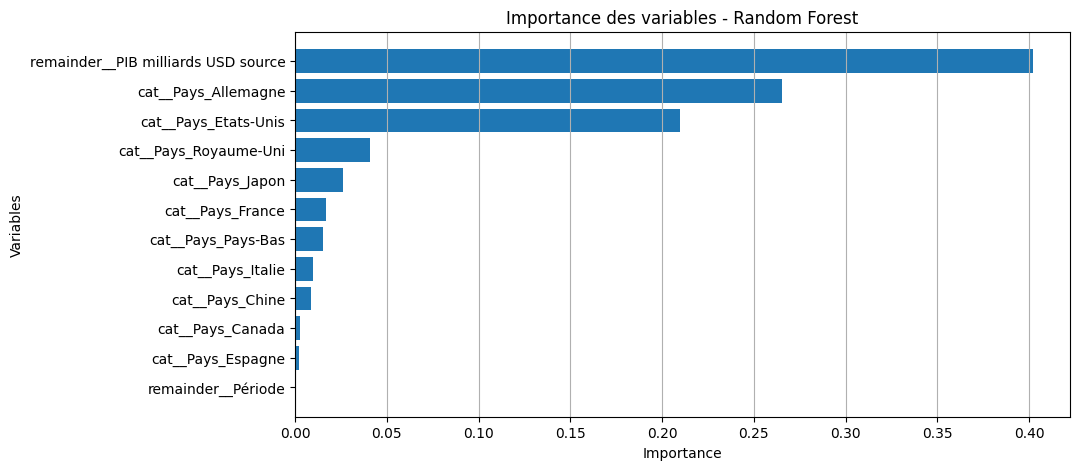

In [66]:
# SECTION 13 : SENSIBILITÉ ET INTERPRÉTATION

# Récupération du modèle Random Forest
modele_rf = modele_foret.named_steps['modele']

# Récupération des noms des variables après prétraitement
noms_variables = modele_foret.named_steps[
    'preparation'
].get_feature_names_out()

# Importance des variables
importance = pd.DataFrame({
    'Variable': noms_variables,
    'Importance': modele_rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance)

# Graphique
plt.figure(figsize=(10, 5))

plt.barh(
    importance['Variable'],
    importance['Importance']
)

plt.title("Importance des variables - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Variables")
plt.gca().invert_yaxis()
plt.grid(axis='x')

plt.show()

Importance des variables :


,Variable,Importance
11,remainder__PIB milliards USD source,0.402179
0,cat__Pays_Allemagne,0.265100
4,cat__Pays_Etats-Unis,0.210015
9,cat__Pays_Royaume-Uni,0.040765
7,cat__Pays_Japon,0.026297
5,cat__Pays_France,0.016925
8,cat__Pays_Pays-Bas,0.015394
6,cat__Pays_Italie,0.009587
2,cat__Pays_Chine,0.008740
1,cat__Pays_Canada,0.002912


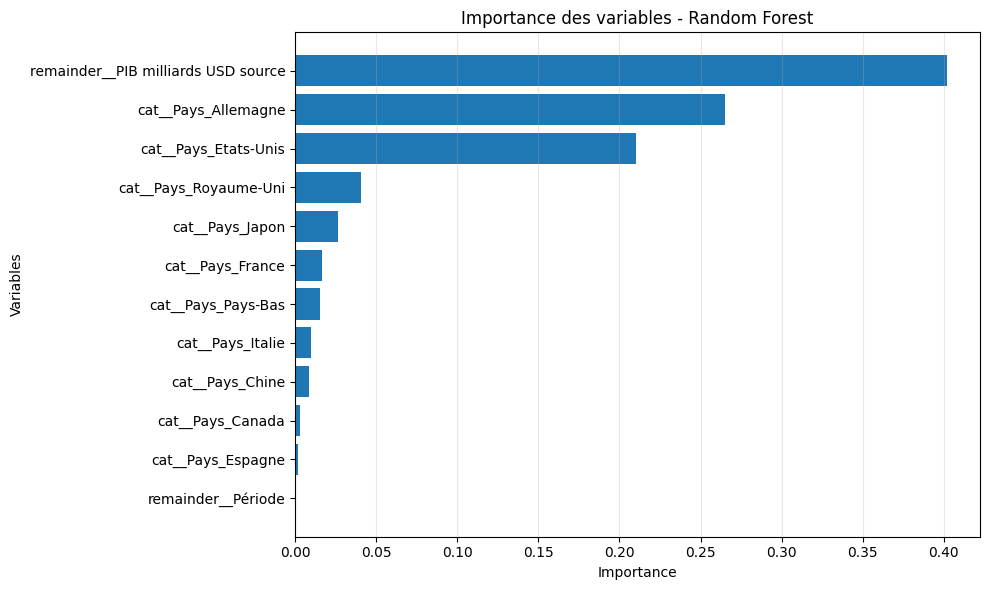

In [67]:
# SECTION 13 : SENSIBILITÉ ET INTERPRÉTATION
# Récupération du modèle Random Forest
modele_rf = modele_foret.named_steps['modele']
# Récupération des noms des variables après prétraitement
noms_variables = modele_foret.named_steps[
    'preparation'
].get_feature_names_out()
# Calcul de l'importance des variables
importance = pd.DataFrame({
    'Variable': noms_variables,
    'Importance': modele_rf.feature_importances_
})
# Classement des variables
importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print("Importance des variables :")
display(importance)
# Graphique
plt.figure(figsize=(10, 6))
plt.barh(
    importance['Variable'],
    importance['Importance']
)
plt.title("Importance des variables - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Variables")
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Conclusion commerciale

**À faire :** Interprétation, limites et recommandations sous conditions.

**Réponse du binôme :** Ce projet avait pour objectif d’analyser et de prédire les importations de légumes de différents pays à partir de leurs caractéristiques économiques, notamment leur PIB.

L’analyse exploratoire a permis d’observer les différences entre les marchés étudiés et de mettre en évidence une relation positive entre le PIB et les importations.

La comparaison des deux modèles, la régression linéaire et Random Forest, permet d’évaluer leur capacité à prédire les importations.

Les résultats obtenus sur les données de test de 2024 permettent de déterminer le modèle le plus performant selon les métriques MAE, RMSE et R².

D’un point de vue commercial, cette étude peut aider les entreprises exportatrices à identifier les marchés présentant un potentiel intéressant, à anticiper la demande et à mieux organiser leurs stratégies commerciales.

Cependant, les résultats présentent certaines limites. La base contient seulement 30 observations, réparties sur 10 pays et trois années. De plus, les importations dépendent également d’autres facteurs qui ne sont pas intégrés dans notre modèle, comme les prix, les politiques commerciales, la production locale et les habitudes de consommation.

Nous recommandons donc d’utiliser le modèle retenu comme un outil d’aide à la décision et non comme une prévision certaine. Une actualisation régulière des données et l’ajout de nouvelles variables permettraient d’améliorer la fiabilité des prédictions.

In [68]:
# SECTION 14 : CONCLUSION COMMERCIALE
# Identification du meilleur modèle selon la RMSE de test
if rmse_lin < rmse_rf:
    meilleur_modele = "Régression linéaire"
    meilleure_rmse = rmse_lin
else:
    meilleur_modele = "Random Forest optimisé"
    meilleure_rmse = rmse_rf
print("CONCLUSION DU PROJET")
print("------------------------------")
print("Meilleur modèle :", meilleur_modele)
print("RMSE sur les données de test :", meilleure_rmse)
print("\nRecommandation commerciale :")
print(
    "Le modèle sélectionné peut aider les entreprises "
    "à anticiper les importations de légumes et à identifier "
    "les marchés présentant un potentiel commercial intéressant."
)
print(
    "\nLes résultats doivent toutefois être interprétés "
    "avec prudence en raison du nombre limité d'observations."
)


CONCLUSION DU PROJET
------------------------------
Meilleur modèle : Régression linéaire
RMSE sur les données de test : 0.9526171425609786

Recommandation commerciale :
Le modèle sélectionné peut aider les entreprises à anticiper les importations de légumes et à identifier les marchés présentant un potentiel commercial intéressant.

Les résultats doivent toutefois être interprétés avec prudence en raison du nombre limité d'observations.


## 15. Reproductibilité

**À faire :** Versions, seed, provenance, exécution intégrale et références.

**Réponse du binôme :** Afin de garantir la reproductibilité de notre projet, nous avons utilisé Python et plusieurs bibliothèques spécialisées dans l’analyse de données et le Machine Learning.

Les principales bibliothèques utilisées sont Pandas, NumPy, Matplotlib et Scikit-learn.

Une graine aléatoire fixe (random_state=42) a été utilisée dans le modèle Random Forest afin de faciliter la reproduction des résultats.

Les données utilisées proviennent du fichier CSV du projet, construit à partir des sources UN Comtrade et Banque mondiale.

Le projet suit un découpage chronologique des données : 2022 pour l’entraînement, 2023 pour la validation et 2024 pour le test.

Cette organisation permet de conserver les mêmes conditions d’analyse et de comparaison des modèles.

In [69]:
# SECTION 15 : REPRODUCTIBILITÉ
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn
# Graine aléatoire
GRAINE_ALEATOIRE = 42
# Affichage des versions
print("ENVIRONNEMENT DU PROJET")
print("------------------------------")
print("Version de Python :", sys.version)
print("Version de NumPy :", np.__version__)
print("Version de Pandas :", pd.__version__)
print("Version de Matplotlib :", matplotlib.__version__)
print("Version de Scikit-learn :", sklearn.__version__)
print("\nParamètres utilisés :")
print("Graine aléatoire :", GRAINE_ALEATOIRE)
print("\nDécoupage des données :")
print("Entraînement : 2022")
print("Validation : 2023")
print("Test : 2024")
print("\nNombre d'observations :", len(df_model))
print("Nombre de pays :", df_model['Pays'].nunique())
print("\nAnnées étudiées :")
print(sorted(df_model['Période'].unique()))
print("\nProjet reproductible avec les mêmes données et paramètres.")

ENVIRONNEMENT DU PROJET
------------------------------
Version de Python : 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Version de NumPy : 2.4.6
Version de Pandas : 2.2.3
Version de Matplotlib : 3.10.0
Version de Scikit-learn : 1.6.1

Paramètres utilisés :
Graine aléatoire : 42

Découpage des données :
Entraînement : 2022
Validation : 2023
Test : 2024

Nombre d'observations : 30
Nombre de pays : 10

Années étudiées :
[np.int64(2022), np.int64(2023), np.int64(2024)]

Projet reproductible avec les mêmes données et paramètres.


In [70]:
import numpy as np
import pandas as pd

pred = modele_lineaire.predict(X_test)
reel = np.asarray(y_test).ravel()

tableau7 = pd.DataFrame({
    "Observation": (
        X_test["Pays"].astype(str) + " - " +
        X_test["Période"].astype(str)
    ),
    "Prédiction": np.round(pred, 2),
    "Valeur réelle": np.round(reel, 2)
})

tableau7["Erreur absolue"] = np.abs(pred - reel)
tableau7["Commentaire"] = [
    f"Surestimation de {abs(p-r):.2f}" if p > r
    else f"Sous-estimation de {abs(p-r):.2f}" if p < r
    else "Prédiction exacte"
    for p, r in zip(pred, reel)
]

tableau7 = (
    tableau7.sort_values("Erreur absolue", ascending=False)
            .head(3)
            .drop(columns="Erreur absolue")
)

print(tableau7.to_string(index=False))

       Observation  Prédiction  Valeur réelle             Commentaire
      Chine - 2024        4.58           1.95   Surestimation de 2.63
 Etats-Unis - 2024       15.24          16.14 Sous-estimation de 0.90
Royaume-Uni - 2024        4.60           5.42 Sous-estimation de 0.82


In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

for nom_ensemble, X, y in [
    ("Validation 2023", X_val, y_val),
    ("Test 2024", X_test, y_test)
]:
    print("\n", nom_ensemble)
    y_reel = np.asarray(y).ravel()

    for nom, modele in {
        "Référence naïve": modele_baseline,
        "Régression linéaire": modele_lineaire,
        "Forêt aléatoire": modele_foret
    }.items():
        y_pred = modele.predict(X)
        rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
        mae = mean_absolute_error(y_reel, y_pred)
        r2 = r2_score(y_reel, y_pred)

        print(nom, "| RMSE =", round(rmse, 3),
              "| MAE =", round(mae, 3),
              "| R² =", round(r2, 3))


 Validation 2023
Référence naïve | RMSE = 4.089 | MAE = 2.767 | R² = -0.005
Régression linéaire | RMSE = 0.655 | MAE = 0.444 | R² = 0.974
Forêt aléatoire | RMSE = 2.117 | MAE = 1.398 | R² = 0.731

 Test 2024
Référence naïve | RMSE = 4.183 | MAE = 2.893 | R² = -0.005
Régression linéaire | RMSE = 0.953 | MAE = 0.615 | R² = 0.948
Forêt aléatoire | RMSE = 2.304 | MAE = 1.572 | R² = 0.695


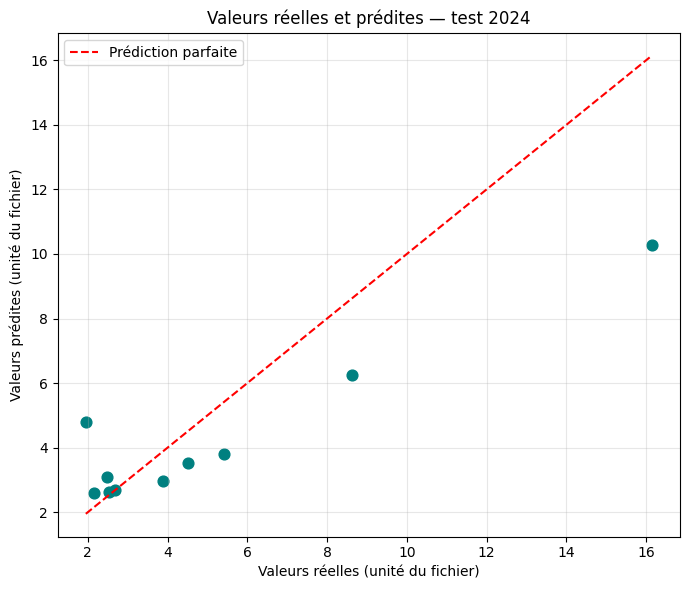

In [72]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Modèle retenu dans le tableau
y_reel = np.asarray(y_test).ravel()
y_pred = modele_foret.predict(X_test)

limite_min = min(y_reel.min(), y_pred.min())
limite_max = max(y_reel.max(), y_pred.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_reel, y_pred, s=60, color="teal")
plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Prédiction parfaite"
)

plt.xlabel("Valeurs réelles (unité du fichier)")
plt.ylabel("Valeurs prédites (unité du fichier)")
plt.title("Valeurs réelles et prédites — test 2024")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/fig4_reel_vs_pred.png", dpi=300, bbox_inches="tight")
plt.show()